# **Problem Statement**

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

# **Objective**

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired the firm EasyVisa for data-driven solutions. You as a data scientist at EasyVisa have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

# **Data Description**

The data contains the different attributes of the employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage: Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full-Time Position; N = Part-Time Position
* case_status: Flag indicating if the Visa was certified or denied

# Importing important libraries

In [10]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# To tune model, get different metric scores, and split data
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# To be used for data scaling and one hot encoding
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

# To impute missing values
from sklearn.impute import SimpleImputer
from sklearn import metrics

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To do hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# To define maximum number of columns to be displayed in a dataframe
pd.set_option("display.max_columns", None)

# To supress scientific notations for a dataframe
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To help with model building
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    BaggingClassifier,
)
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression

# To suppress scientific notations
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To supress warnings
import warnings

warnings.filterwarnings("ignore")

## **Loading Dataset**

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
EasyVisa = pd.read_csv('/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML) /Module 03 : Advanced Machine Learning/week 4 : Advanced Machine Learning Project/EasyVisa.csv')

In [13]:
data = EasyVisa.copy()

## **Data Overview**

In [14]:
data.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.203,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.650,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.860,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.030,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.390,Year,Y,Certified


In [15]:
 data.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.570,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.790,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.850,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.770,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.910,Year,Y,Certified


In [16]:
print('The total number of rows in the given dataset is',data.shape[0]);
print('The total number of columns in the  given dataset is',data.shape[1]);

The total number of rows in the given dataset is 25480
The total number of columns in the  given dataset is 12


* There are 25480 rows and 12 columns in the given dataset

In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


* In the given dataset, the columns 'prevailing_wage','yr_of_estab','no_of_employees' are numerical and remaining columns are categorical
* The dataset has no null values, which means this dataset has no missing values

In [18]:
print('The total number of duplicated data in the dataset are',data.duplicated().sum());

The total number of duplicated data in the dataset are 0


* This dataset has no duplicate values

In [19]:
data.isnull().sum()

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


* There are no missing value in the dataset

In [20]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.000,5667.043,22877.929,-26.000,1022.000,2109.000,3504.000,602069.000
yr_of_estab,25480.000,1979.410,42.367,1800.000,1976.000,1997.000,2005.000,2016.000
prevailing_wage,25480.000,74455.815,52815.942,2.137,34015.480,70308.210,107735.513,319210.270


* The dataset has only 3 numerical columns so the statistical summary between the numericals are shown here
* The no_of_employees column has minimum value in negative, so the columns contain negative value

# **Data Preprocessing**

## **Checking for Anomalous Values**

In [21]:
values = data[data['no_of_employees'] < 0]
print('The total number of negative values in the number of employees in a company column is :',values.shape[0])
negative_values = data.loc[data['no_of_employees'] < 0, 'no_of_employees'].unique()
print('The unique values of negative values in the number of employees in a company column are :',negative_values)

The total number of negative values in the number of employees in a company column is : 33
The unique values of negative values in the number of employees in a company column are : [-25 -11 -17 -26 -14]


* There are 33 rows in the dataset with negative value in the number of employees column
* From the given dataset, I have sorted out the rows with negative values in the number of employees column
* Then I have sorted out 5 negative values in number of employees column, which is repeated for 33 rows with negative value in the dataset

In [22]:
data['no_of_employees'].replace(-25,25,inplace=True)
data['no_of_employees'].replace(-11,11,inplace=True)
data['no_of_employees'].replace(-17,17,inplace=True)
data['no_of_employees'].replace(-26,26,inplace=True)
data['no_of_employees'].replace(-14,14,inplace=True)

* Let's replace the 5 negative values in the number of employees column, which is repeated for 33 rows, with a posit value in the dataset

In [23]:
data["yr_of_estab"].describe()

,yr_of_estab
count,25480.000
mean,1979.410
std,42.367
min,1800.000
25%,1976.000
50%,1997.000
75%,2005.000
max,2016.000


* 6472 employer's company was established were established between 1800 to 1976
* 6535 employer's company was established were established between 1976 to 1997
* 12473 employer's company was established were established between 1997 to 2016  

In [24]:
data['unit_of_wage'].replace('Week',2,inplace=True)
data['unit_of_wage'].replace('Month',3,inplace=True)
data['unit_of_wage'].replace('Year',4,inplace=True)
data['unit_of_wage'].replace('Hour',1,inplace=True)

The numbers [1, 2, 3, 4] in the column represents
* 1 --> Hour
* 2 --> Week
* 3 --> Month
* 4 --> Year

In [25]:
data.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.203,1,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.650,4,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.860,4,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.030,4,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.390,4,Y,Certified


In [26]:
month = data['unit_of_wage'] == 3                             # Boolean mask
data.loc[month, 'prevailing_wage'] = data.loc[month, 'prevailing_wage'] * 12  # Multiply selected rows by 12
data['unit_of_wage'].replace(3,4,inplace=True)

In [27]:
week = data['unit_of_wage'] == 2                             # Boolean mask
data.loc[week, 'prevailing_wage'] = data.loc[week, 'prevailing_wage'] * 52  # Multiply selected rows by 52
data['unit_of_wage'].replace(2,4,inplace=True)

In [28]:
hour = data['unit_of_wage'] == 1                             # Boolean mask
data.loc[hour, 'prevailing_wage'] = data.loc[hour, 'prevailing_wage'] * 2080  # Multiply selected rows by 2080
data['unit_of_wage'].replace(1,4,inplace=True)

#print(hour)

* The every row value in the previling_wage column represents wages for an annum/year

* Initially, The values in the previling_wage column represented the wages according to Hour,Week,Month.

* Now the The values in the previling_wage column represented the wages according to year only

* I converted the value 'Month' in unit_of__wage column to 'year' in unit_of__wage columns, by multiplying 12 (12 months in the year) with previling_wage columns where unit_of__wage is equall to month

* I converted the value 'Week' in unit_of__wage column to 'year' in unit_of__wage columns, by multiplying 52 (52 Weeks in the year) with previling_wage columns where unit_of__wage is equall to week

* I converted the value 'Hour' in unit_of__wage column to 'year' in unit_of__wage columns, by multiplying 2080 (by default hours of week is taken as 40 and total number of weeks in a year is 52.) with previling_wage columns where unit_of__wage is equall to Hour

* By multpling hours of week * number of weeks in a year
  40 * 52 = 2080

In [29]:
data.drop(['case_id','unit_of_wage'],axis = 1, inplace=True)
data.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,full_time_position,case_status
0,Asia,High School,N,N,14513,2007,West,1231782.032,Y,Denied
1,Asia,Master's,Y,N,2412,2002,Northeast,83425.650,Y,Certified
2,Asia,Bachelor's,N,Y,44444,2008,West,122996.860,Y,Denied
3,Asia,Bachelor's,N,N,98,1897,West,83434.030,Y,Denied
4,Africa,Master's,Y,N,1082,2005,South,149907.390,Y,Certified


* The column 'Case_id' is dropped
* The unit_of_wage column can be dropped beacuse the every values in prevailing_wage columns has been converted to year

In [30]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   continent              25480 non-null  object 
 1   education_of_employee  25480 non-null  object 
 2   has_job_experience     25480 non-null  object 
 3   requires_job_training  25480 non-null  object 
 4   no_of_employees        25480 non-null  int64  
 5   yr_of_estab            25480 non-null  int64  
 6   region_of_employment   25480 non-null  object 
 7   prevailing_wage        25480 non-null  float64
 8   full_time_position     25480 non-null  object 
 9   case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 1.9+ MB


* After Converting object columns values to 0 and 1
* Except target column convert every column to numerical columns

In [31]:
data.shape

(25480, 10)

* Because we dropped the 'Case_id' column and 'Unit_of_wages' columns now we having 10 columns

# **Exploratory Data Analysis**

### **Univariate Analysis**

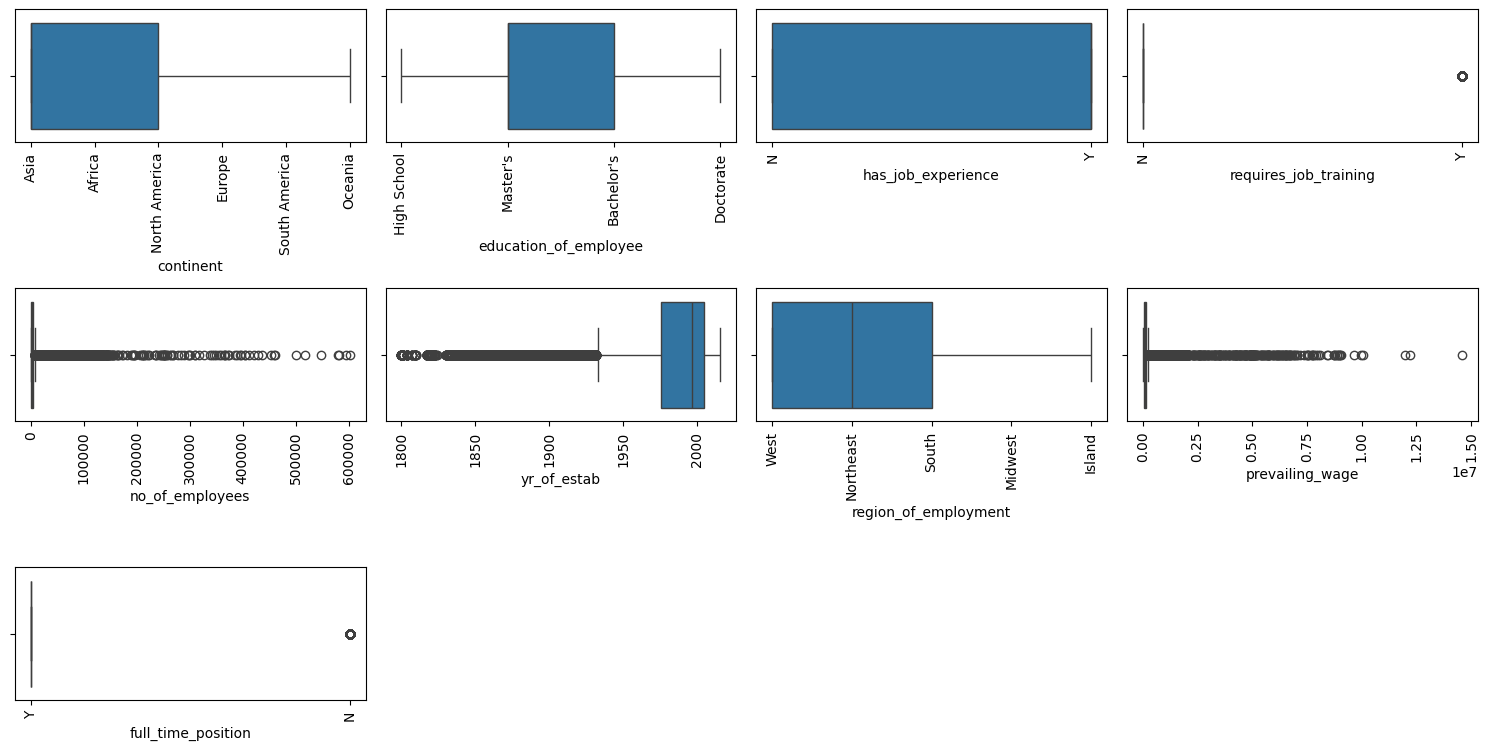

In [32]:
# defining the figure size
plt.figure(figsize=(15, 10))

# defining the list of numerical features to plot
num_features = data[['continent', 'education_of_employee', 'has_job_experience',
       'requires_job_training', 'no_of_employees', 'yr_of_estab',
       'region_of_employment', 'prevailing_wage', 'full_time_position']]

# plotting the histogram for each numerical feature
for i, feature in enumerate(num_features):
    plt.subplot(4, 4, i+1)    # assign a subplot in the main plot
    sns.boxplot(data=data, x=feature)    # plot the histogram
    plt.xticks(rotation=90)
plt.tight_layout();   # to add spacing between plots

By performing Box plot, found that there are outliers in the
  * continent column,
  * required_job_training column,
  * no_of_employees column,
  * yr_of_estab,
  * previling_wage column,
  * full_time_position columns

_______________________________________________________________________________________

Using Boxplot we can't see the data distribution between
  * previling_wage column,
  * no_of_employees column,
  * required_job_training column,
  * full_time_position columns.
_______________________________________________________________________________________

The columns are right skewied
 * continent column
 * education_of_employee
 * yr of estab

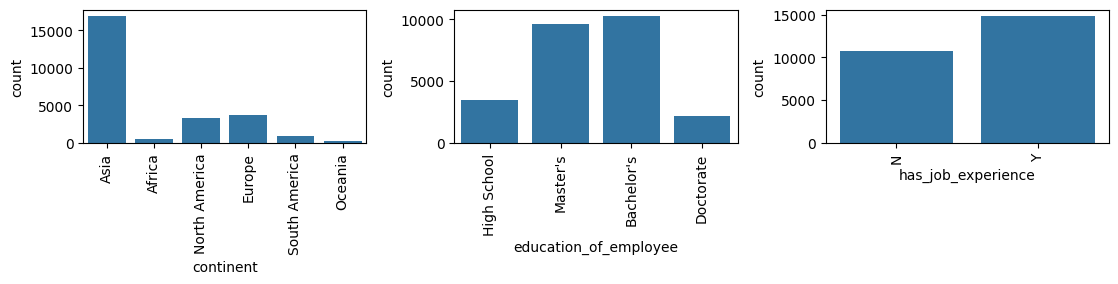

In [33]:
# defining the figure size
plt.figure(figsize=(15, 10))

# defining the list of numerical features to plot
num_features = data[['continent', 'education_of_employee', 'has_job_experience']]

# plotting the histogram for each numerical feature
for i, feature in enumerate(num_features):
    plt.subplot(4, 4, i+1)    # assign a subplot in the main plot
    sns.countplot(data=data, x=feature)    # plot the histogram
    plt.xticks(rotation=90)
plt.tight_layout();   # to add spacing between plots

From the count plot I observed that profiles from the continent column are clustered into
 * 16861 profiles are from Asia
 * 3732 profiles are from Europe
 * 3292 profiles are from North America
 * 852 profiles are from South America
 * 551 profiles are from Africa

__________________________________________________________________________________________

From the count plot I observed that profiles from the education_of_employee column are clustered into
 * 3420 profiles educational background as High School
 * 10234 profiles educational background as Bachelor's Degree
 * 9634 profiles educational background as Master's Degree
 * 2192 profiles educational background are Doctorate

__________________________________________________________________________________________

From the count plot I observed that profiles from the has_job_experience column are clustered into
 * 14802 profiles having job experience
 * 10678 profiles does not having job experience

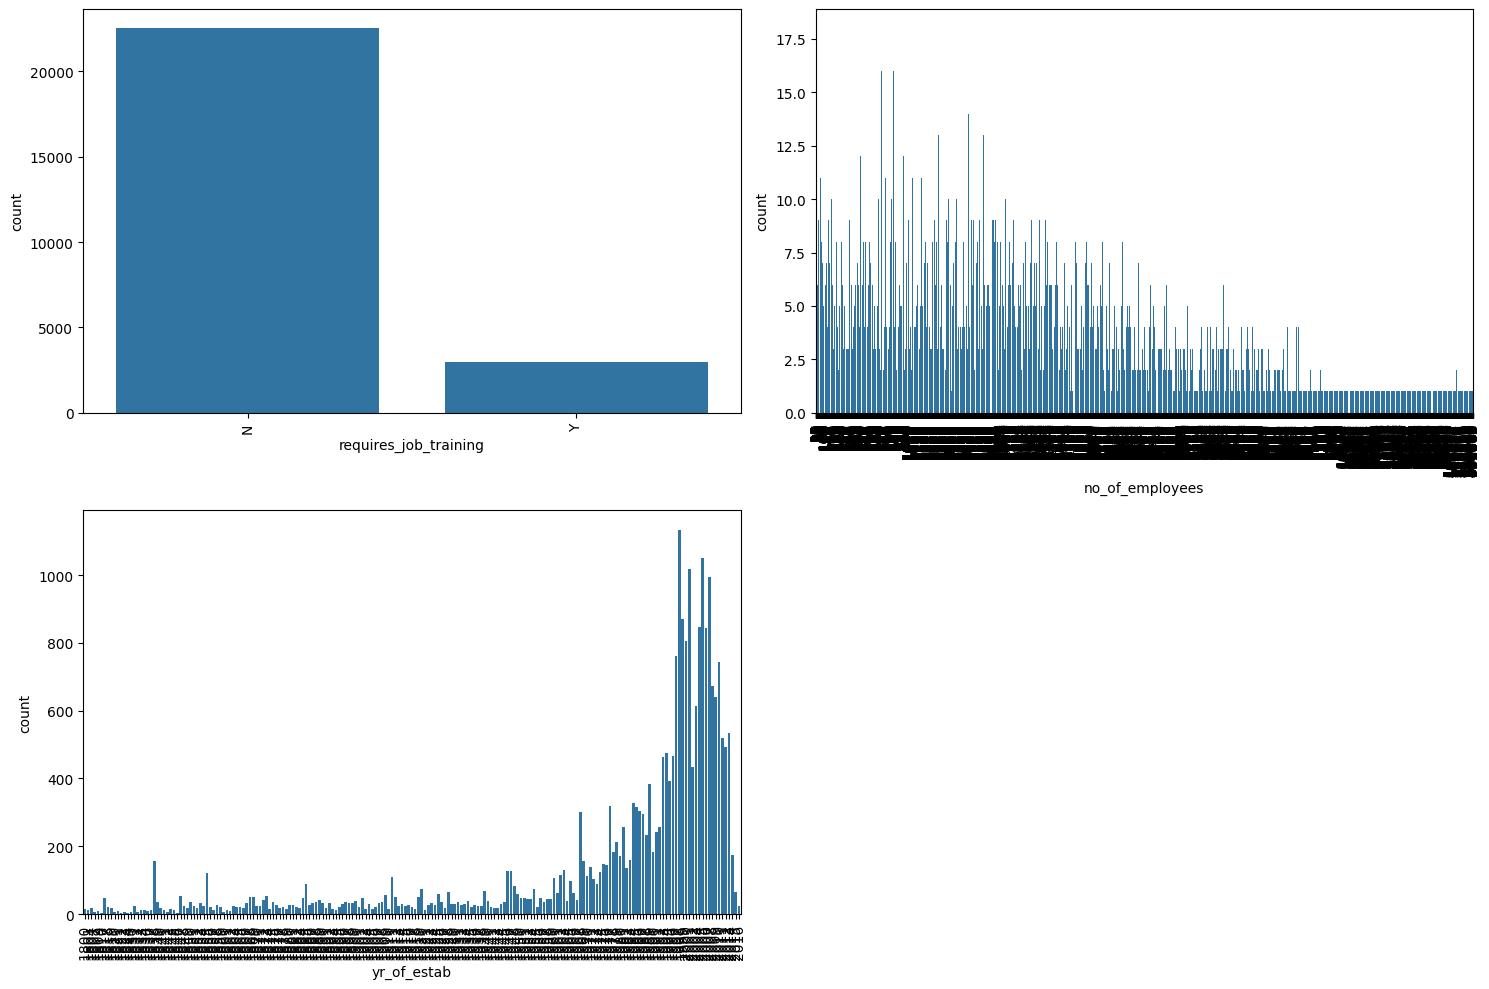

In [34]:
# List of features to plot
num_features = data[['requires_job_training', 'no_of_employees', 'yr_of_estab']]

plt.figure(figsize=(15, 10))
for i, feature in enumerate(num_features):
    plt.subplot(2, 2, i + 1)  # 2x2 grid for up to 4 features
    sns.countplot(data=data, x=feature)
    plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [35]:
year = data[data['yr_of_estab'].between(1800, 1976)]
year1 = data[data['yr_of_estab'].between(1977, 1997)]
year2 = data[data['yr_of_estab'].between(1998, 2016)]

print(year.shape[0], 'are from 1800 to 1976')
print(year1.shape[0], 'are from 1977 to 1997')
print(year2.shape[0], 'are from 1998 to 2016')


experience = data[(data['requires_job_training'] == 'Y') & (data['requires_job_training'] != 'N')]
no_experience = data[(data['requires_job_training'] != 'Y') & (data['requires_job_training'] == 'N')]

print(experience.shape[0],'employee said job traiing needed')
print(no_experience.shape[0],'employee said job training not needed')

6472 are from 1800 to 1976
6535 are from 1977 to 1997
12473 are from 1998 to 2016
2955 employee said job traiing needed
22525 employee said job training not needed


From the countplot I observed that in yr_of_estab column the profiles are clustered into
 * 6472 profiles of employees work in the company which is established between 1800 to 1976
 * 6535 profiles of employees work in the company which is established between 1977 to 1997
 * 12473 profiles of employees work in the company which is established between 1998 to 2016

 ________________________________________________________________________________________

 From the countplot I observed that in requires_job_training column the profiles are clustered into

 * 2955 employee's profiles said they need job training
 * 22525 employee's profiles said they don't need job training




In [36]:
# defining the figure size
plt.figure(figsize=(15, 10))

# defining the list of numerical features to plot
num_features = data[['region_of_employment', 'prevailing_wage', 'full_time_position']]

# plotting the histogram for each numerical feature
for i, feature in enumerate(num_features):
    plt.subplot(4, 4, i+1)    # assign a subplot in the main plot
    sns.countplot(data=data, x=feature)    # plot the histogram
    plt.xticks(rotation=90)
plt.tight_layout();   # to add spacing between plots

Error in callback <function flush_figures at 0x7aec90282200> (for post_execute):


KeyboardInterrupt: 

From the countplot I observed that in prevailing_wage column the data are clustered into
 * The first 25% percent of employee profiles acquiring the wages 47108 per annum
 * The second 25% percent of employee profiles acquiring the wages from 47108 to 82839.5 per annum
 * The third 25% percent of employee profiles acquiring the wages from 82840 to 124825 per annum
 * The maximum wages acquired by the employees profile is 14569149

_______________________________________________________________________________________
From the countplot I observed that in region_of_employment column the data are clustered into
 * 6586 employees profiles are from West
 * 7195 employee profiles are from Northeast
 * 7017 employees profiles are from South
 * 4307 employee profiles are from Midwest
 * 375 employees profiles are from Island

______________________________________________________________________________________________

From the countplot I observed that in full_time_position column the data are clustered into
 * 22773 number of employees profiles has been sorted out as they were working full time
 * 2707 number of employees profiles has been filtered out as they were not working full time

KeyboardInterrupt: 

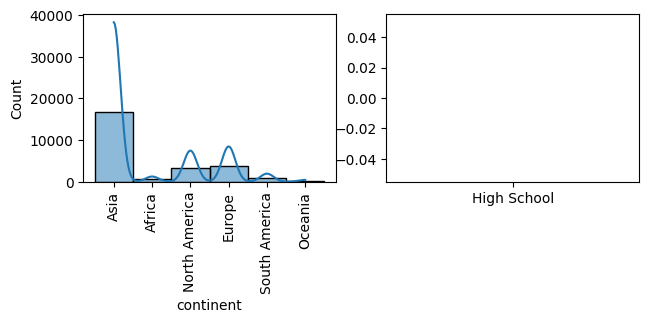

In [37]:
# defining the figure size
plt.figure(figsize=(15, 10))

# defining the list of numerical features to plot
num_features = data[['continent', 'education_of_employee', 'has_job_experience',
       'requires_job_training', 'no_of_employees', 'yr_of_estab',
       'region_of_employment', 'prevailing_wage', 'full_time_position']]

# plotting the histogram for each numerical feature
for i, feature in enumerate(num_features):
    plt.subplot(4, 4, i+1)    # assign a subplot in the main plot
    sns.histplot(data=data, x=feature,kde='True')    # plot the histogram
    plt.xticks(rotation=90)
plt.tight_layout();   # to add spacing between plots

 * Continent : Asia has the highest count, followed by Africa and Europe. Other continents have relatively fewer employee profiles.
________________________________________________________________________________
 * Education of Employee: Education levels Bachelor's and Master's dominate, with Education levels High School and Doctorate appearing much less frequently.
________________________________________________________________________________
 * Has Job Experience: There is a nearly even split between employees with and without job experience, with a slightly higher count for those with experience.
________________________________________________________________________________
 * Requires Job Training: Most employees profile indicates "No" to requiring job training.
________________________________________________________________________________
 * Number of Employees: Highly skewed with most workplaces having low employee counts
________________________________________________________________________________
 * Year of Establishment: Most establishments are relatively recent, especially post-1950, with a strong concentration near the latest years.
________________________________________________________________________________
 * Region of Employment: The "South," "Northeast," and "West" regions have more when compared with "Island" has the lowest.
________________________________________________________________________________
 * Prevailing Wage: Highly skewed distribution with most wages on the lower end and few extreme wage values.
________________________________________________________________________________
 * Full-Time Position: Majority are full-time positions ("Y"), with a smaller proportion of part-time ("N").

In [ ]:
data['continent'].replace('North America','America',inplace=True)
data['continent'].replace('South America','America',inplace=True)


print(100*data['continent'].value_counts(normalize=True), '\n')

sns.histplot(data=data, x='continent',hue='case_status',color='Red');

From the Histogram I observed that visa certified to work for employees profiles are clustered into
 * 66.17% percent of employee profile from Asian continent
 * 14.64% percent of employee profile from Europe continent
 * 16.26% percent of employee profile from America continent
 * 2.16%  percent of employee profile from African continent
 * 0.75%  percent of employee profile from Oceania continent
 _______________________________________________________________________________
 * By sorting out the employees profiles from the continent column as individuals and calculating the percentage of profiles certified for visa from each continent, I found that 79.23% percent of employee profiles are certified from Europe alone

In [ ]:
ContinentAsia = data[data['continent'] == 'Asia']
Continent_Asia = ContinentAsia[ContinentAsia['case_status'] == 'Certified']
Continent_Asian = ContinentAsia[ContinentAsia['case_status'] == 'Denied']

# Calculate the percentage
percentage_Asia = (len(Continent_Asia)/len(ContinentAsia)) * 100
percentage_Asian = (len(Continent_Asian)/len(ContinentAsia)) * 100


print('The total number of employee profiles which are from Asia continent : ',len(ContinentAsia))
print('The total number of employee profiles which are certified for visa are : ',len(Continent_Asia))
print(f"Percentage of employees profile which are certified for visa from Asia Continent: {percentage_Asia:.2f}%")
print(f"Percentage of employees profile which are Denied for visa from Asia Continent: {percentage_Asian:.2f}%")



ContinentEurope = data[data['continent'] == 'Europe']
Continent_Europe = ContinentEurope[ContinentEurope['case_status'] == 'Certified']
Continent_European = ContinentEurope[ContinentEurope['case_status'] == 'Denied']

# Calculate the percentage
percentage_Europe = (len(Continent_Europe)/len(ContinentEurope)) * 100
percentage_European = (len(Continent_European)/len(ContinentEurope)) * 100

print('\n The total number of employee profiles which are from Europe continent : ',len(ContinentEurope))
print(' The total number of employee profiles which are certified for visa are from Europe Continent : ',len(Continent_Europe))
print(f" Percentage of employees profile which are certified for visa from Europe Continent: {percentage_Europe:.2f}%")
print(f" Percentage of employees profile which are Denied for visa from Europe Continent: {percentage_European:.2f}%")



ContinentAmerica = data[data['continent'] == 'America']
Continent_America = ContinentAmerica[ContinentAmerica['case_status'] == 'Certified']
Continent_American = ContinentAmerica[ContinentAmerica['case_status'] == 'Denied']

# Calculate the percentage
percentage_America = (len(Continent_America)/len(ContinentAmerica)) * 100
percentage_American = (len(Continent_American)/len(ContinentAmerica)) * 100

print('\n The total number of employee profiles which are from American continent : ',len(ContinentAmerica))
print(' The total number of employee profiles which are certified for visa are from American Continent : ',len(Continent_America))
print(f" Percentage of employees profile which are certified for visa from American Continent: {percentage_America:.2f}%")
print(f" Percentage of employees profile which are Denied for visa from American Continent: {percentage_American:.2f}%")



ContinentAfrica = data[data['continent'] == 'Africa']
Continent_Africa = ContinentAmerica[ContinentAmerica['case_status'] == 'Certified']
Continent_African = ContinentAmerica[ContinentAmerica['case_status'] == 'Denied']

# Calculate the percentage
percentage_Africa = (len(ContinentAfrica)/len(Continent_Africa)) * 100
percentage_African = (len(ContinentAfrica)/len(Continent_African)) * 100

print('\n The total number of employee profiles which are from Africa continent : ',len(Continent_Africa))
print(' The total number of employee profiles which are certified for visa are from Africa Continent : ',len(ContinentAfrica))
print(f" Percentage of employees profile which are certified for visa from Africa Continent: {percentage_Africa:.2f}%")
print(f" Percentage of employees profile which are Denied for visa from Africa Continent: {percentage_African:.2f}%")



ContinentOceania = data[data['continent'] == 'Oceania']
Continent_Oceania = ContinentOceania[ContinentOceania['case_status'] == 'Certified']
Continent_Oceanian = ContinentOceania[ContinentOceania['case_status'] == 'Denied']

# Calculate the percentage
percentage_Oceania = (len(Continent_Oceania)/len(ContinentOceania)) * 100
percentage_Oceanian = (len(Continent_Oceanian)/len(ContinentOceania)) * 100

print('\n The total number of employee profiles which are from Africa continent : ',len(ContinentOceania))
print(' The total number of employee profiles which are certified for visa are from Africa Continent : ',len(Continent_Oceania))
print(f" Percentage of employees profile which are certified for visa from Africa Continent: {percentage_Oceania:.2f}%")
print(f" Percentage of employees profile which are Denied for visa from Africa Continent: {percentage_Oceanian:.2f}%")


From the Histogram I observed that

 From Asian Continent :
 * 16861 employee profile sorted out from the dataset
 * out of 16861 employee profiles 11012 employees profiles are certified for the visa
 * 65.31% percent of employee profiles from the Asian Continent are certified for visa
 _______________________________________________________________________________

 From Europe Continent :
 * 3732 employee profile sorted out from the dataset
 * out of 3732 employee profiles 2957 employees profiles are certified for the visa
 * 79.23% percent of employee profiles from the European Continent are certified for visa
 _______________________________________________________________________________

 From America Continent :
 * 4144 employee profile sorted out from the dataset
 * out of 4144 employee profiles 2530 employees profiles are certified for the visa
 * 61.05% percent of employee profiles from the American Continent are certified for visa
 _______________________________________________________________________________

 From Africa Continent :
 * 2530 employee profile sorted out from the dataset
 * out of 2530 employee profiles 555 employees profiles are certified for the visa
 * 21.78% percent of employee profiles from the African Continent are certified for visa
________________________________________________________________________________

 From Oceania continent :
 * 192 employee profile sorted out from the dataset
 * out of 192 employee profiles 122 employees profiles are certified for the visa
 * 63.54% percent of employee profiles from the Oceania Continent are certified for visa

In [ ]:
print(100*data['education_of_employee'].value_counts(normalize=True), '\n')
sns.histplot(data=data, x='education_of_employee',hue='case_status',color='Red');

From the Histogram I observed that visa certified to work for employees profiles are clustered into
 * All the employees profiles are Denied for visa whose Educational background as "High School"
 * 40.16% percent of the employees profiles are certified for visa whose Educational background as "Bachelor's"
 * 37.81% percent of the employees profiles are certified for visa whose Educational background as "Master's"
 * 8.60% percent of the employees profiles are certified for visa whose Educational background as "Doctorate"

In [ ]:
education = data[data['education_of_employee'] == "Bachelor's"]
education_Bachelor = education[education['case_status'] == 'Certified']
education_Bachelors = education[education['case_status'] == 'Denied']

# Calculate the percentage
percentage_Bachelor = (len(education_Bachelor)/len(education)) * 100
percentage_Bachelors = (len(education_Bachelors)/len(education)) * 100

print('\n The total number of employee profiles whose educational background as Bachelors : ',len(education))
print(' The total number of employee profiles which are certified for visa whose educational background as Bachelors : ',len(education_Bachelor))
print(f" Percentage of employees profile which are certified for visa whose educational background as Bachelors :  {percentage_Bachelor:.2f}%")
print(f" Percentage of employees profile which are Denied for visa whose educational background as Bachelors :  {percentage_Bachelors:.2f}%")


educationMasters = data[data['education_of_employee'] == "Master's"]
education_Master = educationMasters[educationMasters['case_status'] == 'Certified']
education_Masters = educationMasters[educationMasters['case_status'] == 'Denied']

# Calculate the percentage
percentage_Master = (len(education_Master)/len(educationMasters)) * 100
percentage_Masters = (len(education_Masters)/len(educationMasters)) * 100

print('\n The total number of employee profiles whose educational background as Masters : ',len(educationMasters))
print(' The total number of employee profiles which are certified for visa whose educational background as Masters : ',len(education_Master))
print(f" Percentage of employees profile which are certified for visa whose educational background as Masters :  {percentage_Master:.2f}%")
print(f" Percentage of employees profile which are Denied for visa whose educational background as Masters :  {percentage_Masters:.2f}%")


educationDoctorate = data[data['education_of_employee'] == "Doctorate"]
education_Doctorate = educationDoctorate[educationDoctorate['case_status'] == 'Certified']
education_Doctorates = educationDoctorate[educationDoctorate['case_status'] == 'Denied']

# Calculate the percentage
percentage_Doctorate = (len(education_Doctorate)/len(educationDoctorate)) * 100
percentage_Doctorates = (len(education_Doctorates)/len(educationDoctorate)) * 100

print('\n The total number of employee profiles whose educational background as Doctorate : ',len(educationDoctorate))
print(' The total number of employee profiles which are certified for visa whose educational background as Doctorate : ',len(education_Doctorate))
print(f" Percentage of employees profile which are certified for visa whose educational background as Doctorate :  {percentage_Doctorate:.2f}%")
print(f" Percentage of employees profile which are Denied for visa whose educational background as Doctorate :  {percentage_Doctorates:.2f}%")


 * 10234 employee profiles has educational background as Bachelor's
 * out of 10234 employee profiles 6367 employee profiles are certified for the visa which is 62.21% percent certified for visa and 37.79% percent not certified for visa

 * 9634 employee profiles has educational background as Master's
 * out of 9634 employee profile 7575 employee profiles are certified for the visa which is 78.63% percent certified for visa and 21.37% percent not certified for visa

 * 2192 employee profiles has educational background as Doctorate
 * out of 2192 employee profile 1912 employee profiles are certified for the visa which is 87.23% percent certified for visa and 12.77% percent not certified for visa
 _______________________________________________________________________________


 By analyzing the education of the employee column I observed that the employee profile with Bachelor's  has higher chance for visa denied when comparing with education of employee with Master's and education of employee with Doctorate

In [ ]:
print(100*data['has_job_experience'].value_counts(normalize=True), '\n')
sns.histplot(data=data, x='has_job_experience',hue='case_status',color='Red');

From the Histogram I observed that visa certified to work for employees profiles are clustered into
 * 58.09% percent of the employees profiles are certified for visa to those who have job experience
 * 41.90% percent of the employees profiles are certified for visa to those who have no job experience

In [ ]:

experience = data[data['has_job_experience'] == "Y"]
experience_Y = experience[experience['case_status'] == 'Certified']
experience_N = experience[experience['case_status'] == 'Denied']

# Calculate the percentage
percentage_Y = (len(experience_Y)/len(experience)) * 100
percentage_N = (len(experience_N)/len(experience)) * 100

print('\n The total number of employee profiles who mentioned they have work experience : ',len(experience))
print(' The total number of employee profiles who are all mentioned they have work experience which are certified for visa : ',len(experience_Y))
print(f" Percentage of employees profile mentioned they have work experience which are certified for visa :  {percentage_Y:.2f}%")
print(f" Percentage of employees profile which are Denied mentioned they have work experience:  {percentage_N:.2f}%")


experience1 = data[data['has_job_experience'] == "N"]
experience_Y = experience1[experience1['case_status'] == 'Certified']
experience_N = experience1[experience1['case_status'] == 'Denied']

# Calculate the percentage
percentage_Y = (len(experience_Y)/len(experience1)) * 100
percentage_N = (len(experience_N)/len(experience1)) * 100

print('\n The total number of employee profiles who mentioned they have work experience : ',len(experience1))
print(' The total number of employee profiles who are all mentioned they have work experience which are certified for visa : ',len(experience_Y))
print(f" Percentage of employees profile mentioned they have work experience which are certified for visa :  {percentage_Y:.2f}%")
print(f" Percentage of employees profile which are Denied mentioned they have work experience:  {percentage_N:.2f}%")


 * 14802 number of employees profiles mentioned that they have job experience
 * out of 14802 number of employees profiles 11024 employees profiles are certified for visa which is 74.48% percent of employee profiles are certified for visa

 * 10678 number of employees profiles mentioned that they have no job experienc
 * out of 10678 number of employee profiles 5994 employees profiles are certified for visa which is 56.13% percent of employee profiles are certified for visa
 _______________________________________________________________________________

 By analyzing the employee job experience column I observed that employee who have no job experience has more chance for visa denial when compared with employees with job experience

In [ ]:
print(100*data['requires_job_training'].value_counts(normalize=True), '\n')
sns.histplot(data=data, x='requires_job_training',hue='case_status',color='Red');


 From the Histogram I observed that visa certified to work for employees profiles are clustered into
 * 88.40%  percent of the employees profiles are certified for visa to those who have mentioned they don't job training
 * 11.59% percent of the employees profiles are certified for visa to those who have mentioned they need job training

In [ ]:

training = data[data['requires_job_training'] == "Y"]
training_Y = training[training['case_status'] == 'Certified']
trainings_N = training[training['case_status'] == 'Denied']

# Calculate the percentage
percentage_Y = (len(training_Y)/len(training)) * 100
percentage_N = (len(trainings_N)/len(training)) * 100

print('\n The total number of employee profiles who mentioned they need job training: ',len(training))
print(' The total number of employee profiles who are all mentioned they need job training certified for visa : ',len(training_Y))
print(f" Percentage of employees profile that mentioned they need job training and certified for visa :  {percentage_Y:.2f}%")
print(f" Percentage of employees profile that mentioned they need job training and visas are Denied:  {percentage_N:.2f}%")


training1 = data[data['requires_job_training'] == "N"]
training_Y = training1[training1['case_status'] == 'Certified']
trainings_N = training1[training1['case_status'] == 'Denied']

# Calculate the percentage
percentage_Y = (len(training_Y)/len(training1)) * 100
percentage_N = (len(trainings_N)/len(training1)) * 100

print("\n The total number of employee profiles who mentioned they don't need job training :",len(training1))
print(" The total number of employee profiles who are all mentioned they need don't job training certified for visa  :",len(training_Y))
print(f" Percentage of employees profile mentioned they need don't job training and certified for visa :  {percentage_Y:.2f}%")
print(f" Percentage of employees profile mentioned they need don't job training and denied for visa:  {percentage_N:.2f}%")


* 2955 number of employee profiles mentioned that they need job training
* out of 2955 employee profiles 2006 number of employees profiles are certified for visa which is 67.88%

* 22525 of employee profiles mentioned that they don't need job training
* out of 22525 employee profiles 15012 employees profiles are cerified for visa which is 66.65%
________________________________________________________________________________
By analyzing the job training column I observed that the percentage of visa denied for the employees profiles that mentioned that they need job training and the percentage of visa denied for the employees' profiles that mentioned that they don't need job training  are nearly same

so the employees profiles that mentioned that they need job training or they don't need job training has nothing to do with certified or denied of visa

In [ ]:
# checking the distribution of "Securities_Account" in the bank
print(100*data['region_of_employment'].value_counts(normalize=True), '\n')

# plotting the count plot for Approval
sns.histplot(data=data, x='region_of_employment',hue='case_status',color='Red');

From the Histogram I observed that visa certified to work for employees profiles are clustered into
 * 28.23% percent of the employees profiles are certified for visa to those who have mentioned that they are from Northeast region
 * 27.53% percent of the employees profiles are certified for visa to those who have mentioned that are from south region
 * 25.84% percent of the employees profiles are certified for visa to those who have mentioned that are from west region
 * 16.90% percent of the employees profiles are certified for visa to those who have mentioned that are from Midwest region
 * 1.47% percent of the employees profiles are certified for visa to those who have mentioned that are from Islant

In [ ]:
region = data[data['region_of_employment'] == "West"]
region1 = data[data['region_of_employment'] == "Northeast"]
region2 = data[data['region_of_employment'] == "South"]
region3 = data[data['region_of_employment'] == "Midwest"]
region4 = data[data['region_of_employment'] == "Island"]

region_Y = region[region['case_status'] == 'Certified']
region_N = region[region['case_status'] == 'Denied']

# Calculate the percentage
percentage_Y = (len(region_Y)/len(region)) * 100
percentage_N = (len(region_N)/len(region)) * 100

print('\n The total number of employee profiles who mentioned they are from west region: ',len(region))
print(' The total number of employee profiles who are all mentioned they are from west region and certified for visa : ',len(region_Y))
print(f" Percentage of employees profile that mentioned they are from west region and certified for visa :  {percentage_Y:.2f}%")
print(f" Percentage of employees profile that mentioned they are from west region and visas are Denied:  {percentage_N:.2f}%")

region1_Y = region1[region1['case_status'] == 'Certified']
region1_N = region1[region1['case_status'] == 'Denied']

# Calculate the percentage
percentage1_Y = (len(region1_Y)/len(region1)) * 100
percentage1_N = (len(region1_N)/len(region1)) * 100

print('\n The total number of employee profiles who mentioned they are from Northeast region: ',len(region1))
print(' The total number of employee profiles who are all mentioned they are from Northeast region and certified for visa : ',len(region1_Y))
print(f" Percentage of employees profile that mentioned they are from Northeast region and certified for visa :  {percentage1_Y:.2f}%")
print(f" Percentage of employees profile that mentioned they are from Northeast region and visas are Denied:  {percentage1_N:.2f}%")


region2_Y = region2[region2['case_status'] == 'Certified']
region2_N = region2[region2['case_status'] == 'Denied']

# Calculate the percentage
percentage2_Y = (len(region2_Y)/len(region2)) * 100
percentage2_N = (len(region2_N)/len(region2)) * 100

print('\n The total number of employee profiles who mentioned they are from South region: ',len(region2))
print(' The total number of employee profiles who are all mentioned they are from South region and certified for visa : ',len(region2_Y))
print(f" Percentage of employees profile that mentioned they are from South region and certified for visa :  {percentage2_Y:.2f}%")
print(f" Percentage of employees profile that mentioned they are from South region and visas are Denied:  {percentage2_N:.2f}%")


region3_Y = region3[region3['case_status'] == 'Certified']
region3_N = region3[region3['case_status'] == 'Denied']

# Calculate the percentage
percentage3_Y = (len(region3_Y)/len(region3)) * 100
percentage3_N = (len(region3_N)/len(region3)) * 100

print('\n The total number of employee profiles who mentioned they are from Midwest region: ',len(region3))
print(' The total number of employee profiles who are all mentioned they are from Midwest region and certified for visa : ',len(region3_Y))
print(f" Percentage of employees profile that mentioned they are from Midwest region and certified for visa :  {percentage3_Y:.2f}%")
print(f" Percentage of employees profile that mentioned they are from Midwest region and visas are Denied:  {percentage3_N:.2f}%")


region4_Y = region4[region4['case_status'] == 'Certified']
region4_N = region4[region4['case_status'] == 'Denied']

# Calculate the percentage
percentage4_Y = (len(region4_Y)/len(region4)) * 100
percentage4_N = (len(region4_N)/len(region4)) * 100

print('\n The total number of employee profiles who mentioned they are from Island: ',len(region4))
print(' The total number of employee profiles who are all mentioned they are from Island and certified for visa : ',len(region4_Y))
print(f" Percentage of employees profile that mentioned they are from Island and certified for visa :  {percentage4_Y:.2f}%")
print(f" Percentage of employees profile that mentioned they are from Island and visas are Denied:  {percentage4_N:.2f}%")


 * 6586 employees profile are from west region
 * outoff 6586 employees profiles 4100 employees profiles are certified for visa which 62.25%
 _______________________________________________________________________________
 * 7195 employees profiles are from Northeast region
 * outof 7195 employee profiles 4526 employees profiles are certified for visa which is 62.90%
 _______________________________________________________________________________
 * 7017 employees profiles are from South region
 * outof 7017 employees profiles 4913 employees profiles are certified for visa which is 70.02%
 _______________________________________________________________________________
 * 4307 employees profiles are from Midwest region
 * outoff 4307 employees profiles 3253 employees profiles are certified for visa which is 75.53%
 _______________________________________________________________________________
 * 375 employees profiles are from Island
 * outof 375 employee profiles 226 employees profiles are certified for visa which is 60.27%

In [ ]:
# checking the distribution of "Securities_Account" in the bank
print(100*data['full_time_position'].value_counts(normalize=True), '\n')

# plotting the count plot for Approval
sns.histplot(data=data, x='full_time_position',hue='case_status',color='Red');

From the Histogram I observed that visa certified to work for employees profiles are clustered into

 * 89.37% percent of the employees profiles are certified for visa to those who have mentioned that they are working full time
 * 10.62% percent of the employees profiles are certified for visa to those who have mentioned that they are working part-time

In [ ]:

position = data[data['full_time_position'] == "Y"]
position_Y = position[position['case_status'] == 'Certified']
position_N = position[position['case_status'] == 'Denied']

# Calculate the percentage
percentage_Y = (len(position_Y)/len(position)) * 100
percentage_N = (len(position_N)/len(position)) * 100

print('\n The total number of employee profiles who mentioned they applied for full time position: ',len(position))
print(' The total number of employee profiles who are all mentioned they applied for full time position and certified for visa : ',len(position_Y))
print(f" Percentage of employees profile that mentioned they applied for full time position and certified for visa :  {percentage_Y:.2f}%")
print(f" Percentage of employees profile that mentioned they applied for full time position and visas are Denied:  {percentage_N:.2f}%")


position1 = data[data['full_time_position'] == "N"]
position1_Y = position1[position1['case_status'] == 'Certified']
position1_N = position1[position1['case_status'] == 'Denied']

# Calculate the percentage
percentage1_Y = (len(position1_Y)/len(position1)) * 100
percentage1_N = (len(position1_N)/len(position1)) * 100

print("\n The total number of employee profiles who mentioned applied for part time position :",len(position1))
print(" The total number of employee profiles who are all mentioned they applied for full time positionand and certified for visa  :",len(position1_Y))
print(f" Percentage of employees profile mentioned they need applied for full time position and certified for visa :  {percentage1_Y:.2f}%")
print(f" Percentage of employees profile mentioned they need applied for full time position and denied for visa:  {percentage1_N:.2f}%")


* 22773 employees profiles are mentioned that they are working as full time
* outof 22773 employees profiles 15163 employees profiles are certified for visa which is 66.58%
________________________________________________________________________________
* 2707 employees profiles are mentioned that they are working as part time
* outoff 2707 employees profiles 1855 employees profiles are certified for visa which is 68.53%

### **Bivariate or multivariate Analysis**

In [ ]:
# defining the size of the plot
plt.figure(figsize=(12, 7))

# Select only numerical columns for correlation
numerical_data = data[['no_of_employees', 'yr_of_estab', 'prevailing_wage']]
# plotting the heatmap for correlation
sns.heatmap(numerical_data.corr(),
            annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

In [ ]:
cat_cols = ['continent', 'education_of_employee', 'has_job_experience',
            'requires_job_training', 'region_of_employment', 'full_time_position']
num_cols = ['prevailing_wage', 'no_of_employees', 'yr_of_estab']

for cat_col in cat_cols:
    for num_col in num_cols:
        plt.figure(figsize=(10, 6))
        sns.boxplot(x=cat_col, y=num_col, data=data)
        plt.title(f'Boxplot of {num_col} by {cat_col}')
        plt.xticks(rotation=45)  # Rotate labels for readability
        plt.tight_layout()
        plt.show()


# **Data Preprocessing (Continues..)**

* There are no missing values in the given dataset
* All the negative vlaue in the dataseet are replaced with positive value


## **Feature Engineering**

In [ ]:
data.head()

In [ ]:
data1 =data.copy()

In [ ]:
continent = {"Asia": 1, "America": 2, "Europe": 3, "Africa": 4, "Oceania": 5}
data1["continent"] = data1["continent"].map(continent)

education = {"High School": 1, "Bachelor's": 2, "Master's": 3, "Doctorate": 4}
data1["education_of_employee"] = data1["education_of_employee"].map(education)

region = {"Northeast": 1, "South": 2, "West": 3, "Midwest": 4, "Island": 5}
data1["region_of_employment"] = data1["region_of_employment"].map(region)

position = {"Y": 1, "N": 0}
data1["full_time_position"] = data1["full_time_position"].map(position)

experience = {"Y": 1, "N": 0}
data1["has_job_experience"] = data1["has_job_experience"].map(experience)

training = {"Y": 1, "N": 0}
data1["requires_job_training"] = data1["requires_job_training"].map(training)

In [ ]:
data1.head()

In [ ]:
# Discretize yr_of_estab into quantile-based buckets
data1["yr_of_estab"] = pd.qcut(
    data1["yr_of_estab"],
    q=[0, 0.25, 0.5, 1],
    labels=["1800 to 1976", "1976 to 1997", "1997 to 2016"]
)

print(data1['no_of_employees'].describe())

* Values have been encoded.
* We will do missing value imputation after splitting the data into train, test and validation to avoid data leakage

## Data Preparation for Modeling

In [ ]:
data1['case_status'] = data1['case_status'].replace({'Certified': 1, 'Denied': 0})
X = data1.drop(["case_status"], axis=1)
y = data1["case_status"]

In [ ]:
y.head()

In [ ]:
# Splitting data into training, validation and test set:
# first we split data into 2 parts, say temporary and test

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

# then we split the temporary set into train and validation

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=1, stratify=y_temp)

print(X_train.shape, X_val.shape, X_test.shape)

In [ ]:
print("Number of rows in train data =", X_train.shape[0])
print("Number of rows in validation data =", X_val.shape[0])
print("Number of rows in test data =", X_test.shape[0])

* The shape of the dataset for training set is 15288
* The shape of the dataset for Validation set is 5096
* The shape of the dataset for testing set is 5096

## Missing Value Treatment

In [ ]:
data1.isnull().sum()

There are no missing values in the given dataset

In [ ]:
# Checking that no column has missing values in train, validation or test sets
print(X_train.isna().sum())
print("-" * 30)
print(X_val.isna().sum())
print("-" * 30)
print(X_test.isna().sum())

There is no missing value in Training set,Validation set and testing set

## Reverse Mapping for Encoded Variables

In [ ]:
## Function to inverse the encoding
def inverse_mapping(x, y):
    inv_dict = {v: k for k, v in x.items()}
    X_train[y] = np.round(X_train[y]).map(inv_dict).astype("category")
    X_val[y] = np.round(X_val[y]).map(inv_dict).astype("category")
    X_test[y] = np.round(X_test[y]).map(inv_dict).astype("category")

In [ ]:
inverse_mapping(continent, "continent")
inverse_mapping(education, "education_of_employee")
inverse_mapping(region, "region_of_employment")
inverse_mapping(experience, "has_job_experience")
inverse_mapping(position, "full_time_position")
inverse_mapping(experience, "has_job_experience")
inverse_mapping(training, "requires_job_training")

In [ ]:
data1.head()

In [ ]:
for col in X_train.columns:
    print(f"Value counts for column: {col}")
    print(X_train[col].value_counts(dropna=False))  # include NaN counts
    print("*" * 40, "\n")  # separator for readability


In [ ]:
for col in X_val.columns:
    print(f"Value counts for column: {col}")
    print(X_train[col].value_counts(dropna=False))  # include NaN counts
    print("*" * 40, "\n")  # separator for readability


In [ ]:
for col in X_test.columns:
    print(f"Value counts for column: {col}")
    print(X_train[col].value_counts(dropna=False))  # include NaN counts
    print("*" * 40, "\n")  # separator for readability


## Creating Dummy Variables

In [ ]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_train = X_train.astype(float)

X_val = pd.get_dummies(X_val, drop_first=True)
X_val = X_val.astype(float)

X_test = pd.get_dummies(X_test, drop_first=True)
X_test = X_test.astype(float)

print(X_train.shape, X_val.shape, X_test.shape)

* After encoding there are 17 columns.

# Model Building

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [ ]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

## Initial Model Building

### Model Building - Original Data

In [ ]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced'), random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1, class_weight='balanced')))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("dtree", DecisionTreeClassifier(random_state=1, class_weight='balanced')))

print("\nTraining Performance:\n")
for name, model in models:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_train)
    scores = recall_score(y_train, y_pred)  # Use the actual positive class label string
    print(f"{name}: {scores}")


print("\nValidation Performance:\n")
for name, model in models:
    model.fit(X_train, y_train)
    scores_val = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores_val))

In [ ]:
print("\nTraining and Validation Performance Difference based on Recall score:\n")

for name, model in models:
    model.fit(X_train, y_train)
    scores_train = recall_score(y_train, model.predict(X_train))
    scores_val = recall_score(y_val, model.predict(X_val))
    difference1 = scores_train - scores_val
    print("{}: Training Score: {:.4f}, Validation Score: {:.4f}, Difference: {:.4f}".format(name, scores_train, scores_val, difference1*100))

* While building different model with original dataset I observed that
    * Decision tree model with Bagging classifier perform well on training dataset and in validation dataset the performance dropped nearly 15%
    * Decision tree model with Random Forest classifier perform well on training dataset and in validation dataset the performance dropped nearly 17.5%
    * Decision tree model with Gradient Boosting method classifier perform well on training dataset and in validation dataset the performance dropped nearly 2%
    * Decision tree model with Adaboost perform well on training dataset and in validation dataset the performance dropped nearly 1.6%
    * A Simple Decision tree model perform well on training dataset and in validation dataset the performance dropped nearly 28%
________________________________________________________________________________

- GBM model and Adaboost model has the best performance followed by Random Forest model,Bagging classifier model and Simple decision tree as per the validation performance

### Model Building - Oversampled Data

In [ ]:
print("Before Oversampling, counts of label 'Yes': {}".format(sum(y_train == 1)))
print("Before Oversampling, counts of label 'No': {} \n".format(sum(y_train == 0)))

sm = SMOTE(
    sampling_strategy=1, k_neighbors=5, random_state=1
)  # Synthetic Minority Over Sampling Technique
X_train_over, y_train_over = sm.fit_resample(X_train, y_train)


print("After Oversampling, counts of label 'Yes': {}".format(sum(y_train_over == 1)))
print("After Oversampling, counts of label 'No': {} \n".format(sum(y_train_over == 0)))


print("After Oversampling, the shape of train_X: {}".format(X_train_over.shape))
print("After Oversampling, the shape of train_y: {} \n".format(y_train_over.shape))

In [ ]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced'), random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1, class_weight='balanced')))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("dtree", DecisionTreeClassifier(random_state=1, class_weight='balanced')))

print("\n" "Training Performance:" "\n")
for name, model in models:
    model.fit(X_train_over, y_train_over)
    scores = recall_score(y_train_over, model.predict(X_train_over))
    print("{}: {}".format(name, scores))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train_over, y_train_over)
    scores = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))

In [ ]:
print("\nTraining and Validation Performance Difference of recall score:\n")

for name, model in models:
    model.fit(X_train_over, y_train_over)
    scores_train = recall_score(y_train_over, model.predict(X_train_over))
    scores_val = recall_score(y_val, model.predict(X_val))
    difference2 = scores_train - scores_val
    print("{}: Training Score: {:.4f}, Validation Score: {:.4f}, Difference: {:.4f}".format(name, scores_train, scores_val, difference2*100))

* While building different model with Oversampled dataset I observed that
    * Decision tree model with Bagging classifier perform well on training dataset and in validation dataset the performance dropped nearly 17%
    * Decision tree model with Random Forest classifier perform well on training dataset and in validation dataset the performance dropped nearly 18.27%
    * Decision tree model with Gradient Boosting method classifier perform well on training dataset and in validation dataset the performance dropped nearly 2%
    * Decision tree model with Adaboost perform well on training dataset and in validation dataset the performance dropped nearly 1.3%
    * A Simple Decision tree model perform well on training dataset and in validation dataset the performance dropped nearly 27.59%
________________________________________________________________________________

- GBM model and Adaboost model has the best performance while comparing with Random Forest model,Bagging classifier model and Simple decision tree as per the validation performance

### Model Building - Undersampled Data

In [ ]:
rus = RandomUnderSampler(random_state=1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)

print("Before Under Sampling, counts of label 'Yes': {}".format(sum(y_train == 1)))
print("Before Under Sampling, counts of label 'No': {} \n".format(sum(y_train == 0)))

print("After Under Sampling, counts of label 'Yes': {}".format(sum(y_train_un == 1)))
print("After Under Sampling, counts of label 'No': {} \n".format(sum(y_train_un == 0)))

print("After Under Sampling, the shape of train_X: {}".format(X_train_un.shape))
print("After Under Sampling, the shape of train_y: {} \n".format(y_train_un.shape))

In [ ]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1, class_weight='balanced'), random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1, class_weight='balanced')))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("dtree", DecisionTreeClassifier(random_state=1, class_weight='balanced')))


print("\n" "Training Performance:" "\n")
for name, model in models:
    model.fit(X_train_un, y_train_un)
    scores = recall_score(y_train_un, model.predict(X_train_un))
    print("{}: {}".format(name, scores))

print("\n" "Validation Performance:" "\n")

for name, model in models:
    model.fit(X_train_un, y_train_un)
    scores = recall_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))

In [ ]:
print("\nTraining and Validation Performance Difference:\n")

for name, model in models:
    model.fit(X_train_un, y_train_un)
    scores_train = recall_score(y_train_un, model.predict(X_train_un))
    scores_val = recall_score(y_val, model.predict(X_val))
    difference3 = scores_train - scores_val
    print("{}: Training Score: {:.4f}, Validation Score: {:.4f}, Difference: {:.4f}".format(name, scores_train, scores_val, difference3*100))

* While building different model with Undersampled dataset I observed that
    * Decision tree model with Bagging classifier perform well on training dataset and in validation dataset the performance dropped nearly 30%
    * Decision tree model with Random Forest classifier perform well on training dataset and in validation dataset the performance dropped nearly 36.26%
    * Decision tree model with Gradient Boosting method classifier perform well on training dataset and in validation dataset the performance dropped nearly 3.26%
    * Decision tree model with Adaboost perform well on training dataset and in validation dataset the performance dropped nearly 2.79%
    * A Simple Decision tree model perform well on training dataset and in validation dataset the performance dropped nearly 42.66%
________________________________________________________________________________

- GBM model and Adaboost model has the best performance while comparing with Random Forest model,Bagging classifier model and Simple decision tree as per the validation performance

when comparing the decision tree models using Undersampled Data and Oversampled Data I observed that

 * Oversampled Data :
   * The perforamce of Decision tree with Bagging Classifier on validation set decreased 17.20% when compared with training set
 * Undersampled Data :
   * The perforamce of Decision tree with Bagging Classifier on validation set decreased 30.85% when compared with training set
________________________________________________________________________________

 * Oversampled Data :
   * The perforamce of Decision tree with Random Forest Classifier on validation set decreased 18.27% when compared with training set
 * Undersampled Data :
   * The perforamce of Decision tree with Random Forest Classifier on validation set decreased 36.26% when compared with training set
________________________________________________________________________________

 * Oversampled Data :
   * The perforamce of Decision tree with Gradient Boosting Classifier on validation set decreased 2% when compared with training set
 * Undersampled Data :
   * The perforamce of Decision tree with Gradient Boosting Classifier on validation set decreased 3.26% when compared with training set
________________________________________________________________________________

* Oversampled Data :
   * The perforamce of Decision tree with Adaboost Classifier on validation set decreased 1.3% when compared with training set
 * Undersampled Data :
   * The perforamce of Decision tree with Adaboost Boosting Classifier on validation set decreased 2.79% when compared with training set
________________________________________________________________________________

* Oversampled Data :
   * The perforamce of simple Decision tree on validation set decreased 27.59% when compared with training set
 * Undersampled Data :
   * The perforamce of simple Decision tree on validation set decreased 42.66% when compared with training set

________________________________________________________________________________

* When comparing the models of different decision trees with  Undersampled data and Oversampled data,
   * The decision tree with Gradient Boosting using oversampled data and the decision tree with Adaboost classifier using oversampled data perform good

* 1% ~ 2% is the difference between training set and validation set of the decision tree with GBM classifier and Adaboost Classifier using oversampled data

## Hyperparameter Tuning

## Tuning Adaboost clasifier model with undersampled data

In [ ]:
# defining model
Model = AdaBoostClassifier(random_state=1)


parameters = {
              'class_weight': ['balanced'],
              'criterion': ['gini'],
              'max_depth': [2, 4, 6],
              'max_leaf_nodes': [50, 75, 150, 250],
              'min_samples_leaf': [1, 2, 5],
              'min_samples_split': [10, 30, 50, 70],
              'splitter': ['best']
              }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.recall_score)

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=model,
    param_distributions=parameters,
    n_iter=50,
    scoring=scorer,
    cv=5,
    n_jobs=-1,
    random_state=1
)

randomized_cv.fit(X_train_un, y_train_un)

print("Best parameters are {} :" .format(randomized_cv.best_params_))
print(" CV score={}:" .format(randomized_cv.best_score_*100))

In [ ]:
tuned_adaboost = AdaBoostClassifier(
    random_state=1,
    n_estimators=20,
    learning_rate=0.01,
    estimator=DecisionTreeClassifier(max_depth=2, random_state=1),
)


tuned_adaboost.fit(X_train_over, y_train_over)

In [ ]:
# Checking model's performance on training set
adaboost_train_un = model_performance_classification_sklearn(tuned_adaboost, X_train_over, y_train_over)
adaboost_train_un

In [ ]:
# Checking model's performance on validation set
adaboost_val_un = model_performance_classification_sklearn(tuned_adaboost, X_val, y_val)
adaboost_val_un

## Tuning Adaboost Classifier model with Oversampled data

In [ ]:
# defining model
Model = AdaBoostClassifier(random_state=1)


parameters = {
              'class_weight': ['balanced'],
              'criterion': ['gini'],
              'max_depth': [2, 4, 6],
              'max_leaf_nodes': [50, 75, 150, 250],
              'min_samples_leaf': [1, 2, 5],
              'min_samples_split': [10, 30, 50, 70],
              'splitter': ['best']
              }

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.recall_score)

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=model,
    param_distributions=parameters,
    n_iter=50,
    scoring=scorer,
    cv=5,
    n_jobs=-1,
    random_state=1
)
randomized_cv.fit(X_train_over, y_train_over)


#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over, y_train_over)

print("Best parameters are {} :" .format(randomized_cv.best_params_))
print(" CV score={}:" .format(randomized_cv.best_score_*100))

In [ ]:
tuned_adaboost = AdaBoostClassifier(
    random_state=1,
    n_estimators=20,
    learning_rate=0.01,
    estimator=DecisionTreeClassifier(max_depth=6, random_state=1),
)


tuned_adaboost.fit(X_train_over, y_train_over)

In [ ]:
# Checking model's performance on training set
adaboost_train_over = model_performance_classification_sklearn(tuned_adaboost, X_train_over, y_train_over)
adaboost_train_over

In [ ]:
# Checking model's performance on validation set
adaboost_val_over = model_performance_classification_sklearn(tuned_adaboost, X_val, y_val)
adaboost_val_over

Summary :
 * After performing the hyper parameter on the Adaboost classifier with oversampled data, the cv score is 87.84% percent.
 * The performance of model on training set is 88% and validation set has a recall score 88% percent.


## Tuning Gradient Boosting Classifier model with Undersampled data

In [ ]:
# defining model
Model1 = GradientBoostingClassifier(random_state=1)

parameters1 = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(125,175,25),
    "learning_rate": [0.01, 0.2, 0.05, 1],
    "subsample":[0.8,0.9,1],
    "max_features":[0.5,0.7,1],
              }



# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.recall_score)

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model1, param_distributions=parameters1, n_iter=50, scoring=scorer, cv=5, random_state=1, n_jobs = -1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_un,y_train_un)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

In [ ]:
tuned_gbm2 = GradientBoostingClassifier(
    random_state=1,
    subsample=1,
    n_estimators=150,
    max_features=1,
    learning_rate=0.2,
    init=AdaBoostClassifier(random_state=1),
)
tuned_gbm2.fit(X_train_un, y_train_un)

In [ ]:
GBM_train_un = model_performance_classification_sklearn(tuned_gbm2, X_train_un, y_train_un)
GBM_train_un

In [ ]:
GBM_val_un = model_performance_classification_sklearn(tuned_gbm2, X_val, y_val)
GBM_val_un

### Tuning Gradient Boosting Classifier model with Oversampled data

In [ ]:
# defining model
Model1 = GradientBoostingClassifier(random_state=1)

parameters1 = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(125,175,25),
    "learning_rate": [0.01, 0.2, 0.05, 1],
    "subsample":[0.8,0.9,1],
    "max_features":[0.5,0.7,1],
              }



# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.recall_score)

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(estimator=Model1, param_distributions=parameters1, n_iter=50, scoring=scorer, cv=5, random_state=1, n_jobs = -1)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over,y_train_over)

print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

In [ ]:
tuned_gbm1 = GradientBoostingClassifier(
    random_state=1,
    subsample=1,
    n_estimators=150,
    max_features=1,
    learning_rate=0.2,
    init=AdaBoostClassifier(random_state=1),
)
tuned_gbm1.fit(X_train_over, y_train_over)

In [ ]:
GBM_train_over = model_performance_classification_sklearn(tuned_gbm1, X_train_over, y_train_over)
GBM_train_over

In [ ]:
GBM_val_over = model_performance_classification_sklearn(tuned_gbm1, X_val, y_val)
GBM_val_over

Summary :
 * After performing the hyper parameter on the Gradient Boosting classifier with oversampled data, the cv score is 87.99% percent.
 * The performance of model on training set and validation set has a recall score 89.5% percent.


# Model Comparison and Final Model Selection

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        adaboost_train_un.T,
        adaboost_train_over.T,
        GBM_train_un.T,
        GBM_train_over.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Gradient boosting trained with Undersampled data",
    "Gradient boosting trained with Oversampled data",
    "AdaBoost trained with undersampled data",
    "AdaBoost trained with oversampled data",
]
print("Training performance comparison:")
models_train_comp_df

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        adaboost_val_un.T,
        adaboost_val_over.T,
        GBM_val_un.T,
        GBM_val_over.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "AdaBoost validated with undersampled data",
    "AdaBoost validated with oversampled data",
     "Gradient boosting validated with Undersampled data",
    "Gradient boosting validated with Oversampled data",
]
print("Training performance comparison:")
models_train_comp_df

- Gradient Boosting  model trained with Oversampled data has generalised performance, so let's consider it as the best model.

In [ ]:
# Let's check the performance on test set
GBM_test = model_performance_classification_sklearn(tuned_gbm1, X_test, y_test)
GBM_test

- The Gradient Boosting model trained on oversampled data has given ~89.5% recall on the validation set and 88.8% percent recall on the unseen test set
- This performance is in line with what we achieved with this model on the train and validation sets
- So, this is a generalized model

# Feature Importance

In [ ]:
feature_names = X_train.columns
importances = tuned_gbm1.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

# Business Insights

 * Employee profile with education background Master's, High school and Doctorate have given more importance
 * Profiles of the employees who are working in the company's which is established between 1997~2016 are given more importance
 * Profiles of employees who are from Europe, America, Asia are given more importance
 * Profiles of the employees who are all Northeast, South and west region of the continent are given more importance
 * Profiles of the employees who metioned they are working in full time position and want job training are given more importance